In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


In [2]:
df = pd.read_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/train_with_features.csv')
store_1 = pd.read_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_1_data.csv')

# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)   # IMPORTANT fix
store_1['Date'] = store_1['Date'].astype(str).str.strip()
store_1['Date'] = pd.to_datetime(store_1['Date'], format='%d-%m-%Y')

print("✅ Data loaded successfully!")
print(f"\nFull dataset shape: {df.shape}")
print(f"Store 1 shape: {store_1.shape}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")


✅ Data loaded successfully!

Full dataset shape: (1017209, 25)
Store 1 shape: (781, 27)
Date range: 2013-01-01 to 2015-07-31


In [3]:
print("="*80)
print("SAMPLE DATA")
print("="*80)
display(store_1[['Date', 'Sales', 'Customers', 'Open', 'Promo', 'DayOfWeek']].head(10))

SAMPLE DATA


,Date,Sales,Customers,Open,Promo,DayOfWeek
0,2013-01-02,5530,668,1,0,3
1,2013-01-03,4327,578,1,0,4
2,2013-01-04,4486,619,1,0,5
3,2013-01-05,4997,635,1,0,6
4,2013-01-07,7176,785,1,1,1
5,2013-01-08,5580,654,1,1,2
6,2013-01-09,5471,626,1,1,3
7,2013-01-10,4892,615,1,1,4
8,2013-01-11,4881,592,1,1,5
9,2013-01-12,4952,646,1,0,6


In [4]:
store_1_open = store_1[store_1['Open'] == 1].copy()
store_1_open = store_1_open.sort_values('Date').reset_index(drop=True)

print("="*80)
print("STORE 1 - OPEN DAYS ONLY")
print("="*80)
print(f"Total records: {len(store_1_open)}")
print(f"Date range: {store_1_open['Date'].min().date()} to {store_1_open['Date'].max().date()}")
print(f"Average daily sales: ${store_1_open['Sales'].mean():,.2f}")
print(f"Median daily sales: ${store_1_open['Sales'].median():,.2f}")
print(f"Total sales: ${store_1_open['Sales'].sum():,.0f}")


STORE 1 - OPEN DAYS ONLY
Total records: 781
Date range: 2013-01-02 to 2015-07-31
Average daily sales: $4,759.10
Median daily sales: $4,647.00
Total sales: $3,716,854


In [5]:
test_weeks = 6
test_start_date = store_1_open['Date'].max() - timedelta(weeks=test_weeks)

train = store_1_open[store_1_open['Date'] < test_start_date].copy()
test = store_1_open[store_1_open['Date'] >= test_start_date].copy()

print("="*80)
print("TRAIN/TEST SPLIT")
print("="*80)
print(f"Training set:")
print(f"  - Records: {len(train)}")
print(f"  - Date range: {train['Date'].min().date()} to {train['Date'].max().date()}")
print(f"  - Average sales: ${train['Sales'].mean():,.2f}")
print(f"\nTest set:")
print(f"  - Records: {len(test)}")
print(f"  - Date range: {test['Date'].min().date()} to {test['Date'].max().date()}")
print(f"  - Average sales: ${test['Sales'].mean():,.2f}")
print(f"\nSplit ratio: {len(train)/(len(train)+len(test))*100:.1f}% train, {len(test)/(len(train)+len(test))*100:.1f}% test")

TRAIN/TEST SPLIT
Training set:
  - Records: 744
  - Date range: 2013-01-02 to 2015-06-18
  - Average sales: $4,777.60

Test set:
  - Records: 37
  - Date range: 2015-06-19 to 2015-07-31
  - Average sales: $4,387.03

Split ratio: 95.3% train, 4.7% test


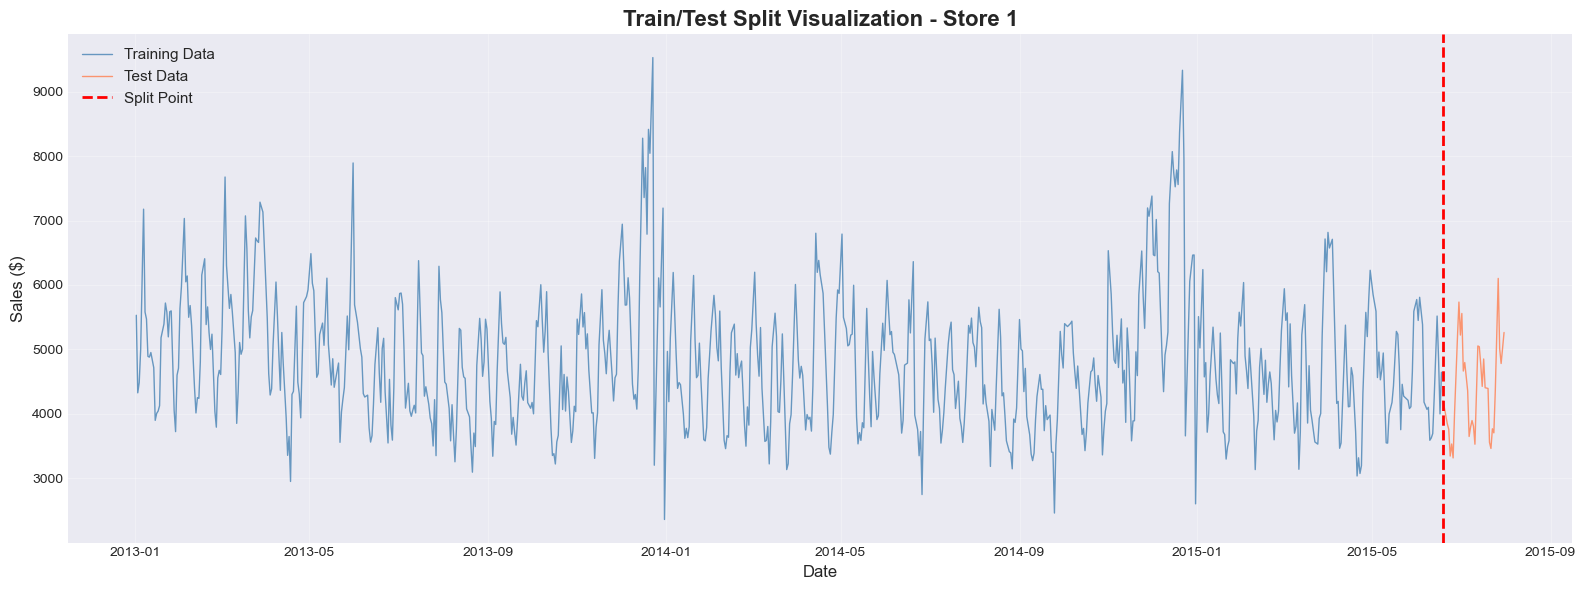

# Observation: Test set covers recent 6 weeks - most relevant for forecasting


In [6]:
plt.figure(figsize=(16, 6))
plt.plot(train['Date'], train['Sales'], label='Training Data', linewidth=1, alpha=0.8, color='steelblue')
plt.plot(test['Date'], test['Sales'], label='Test Data', linewidth=1, alpha=0.8, color='coral')
plt.axvline(test_start_date, color='red', linestyle='--', linewidth=2, label='Split Point')
plt.title('Train/Test Split Visualization - Store 1', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("# Observation: Test set covers recent 6 weeks - most relevant for forecasting")


In [7]:
def calculate_mape(y_true, y_pred):
    """
    Calculate Mean Absolute Percentage Error
    Lower is better. Industry standard for forecast accuracy.
    """
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def evaluate_model(y_true, y_pred, model_name):
    """
    Calculate all evaluation metrics for a model
    """
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = calculate_mape(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print(f"="*80)
    print(f"{model_name} - PERFORMANCE METRICS")
    print(f"="*80)
    print(f"MAE (Mean Absolute Error):     ${mae:,.2f}")
    print(f"RMSE (Root Mean Squared Error): ${rmse:,.2f}")
    print(f"MAPE (Mean Absolute % Error):   {mape:.2f}%")
    print(f"R² Score:                       {r2:.4f}")
    print(f"\n💡 Interpretation:")
    print(f"   - On average, predictions are off by ${mae:,.0f}")
    print(f"   - Typical forecast error: {mape:.1f}%")
    
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}

print("Evaluation functions defined!")

Evaluation functions defined!


NAIVE FORECAST - PERFORMANCE METRICS
MAE (Mean Absolute Error):     $439.97
RMSE (Root Mean Squared Error): $601.35
MAPE (Mean Absolute % Error):   9.65%
R² Score:                       0.3194

💡 Interpretation:
   - On average, predictions are off by $440
   - Typical forecast error: 9.7%


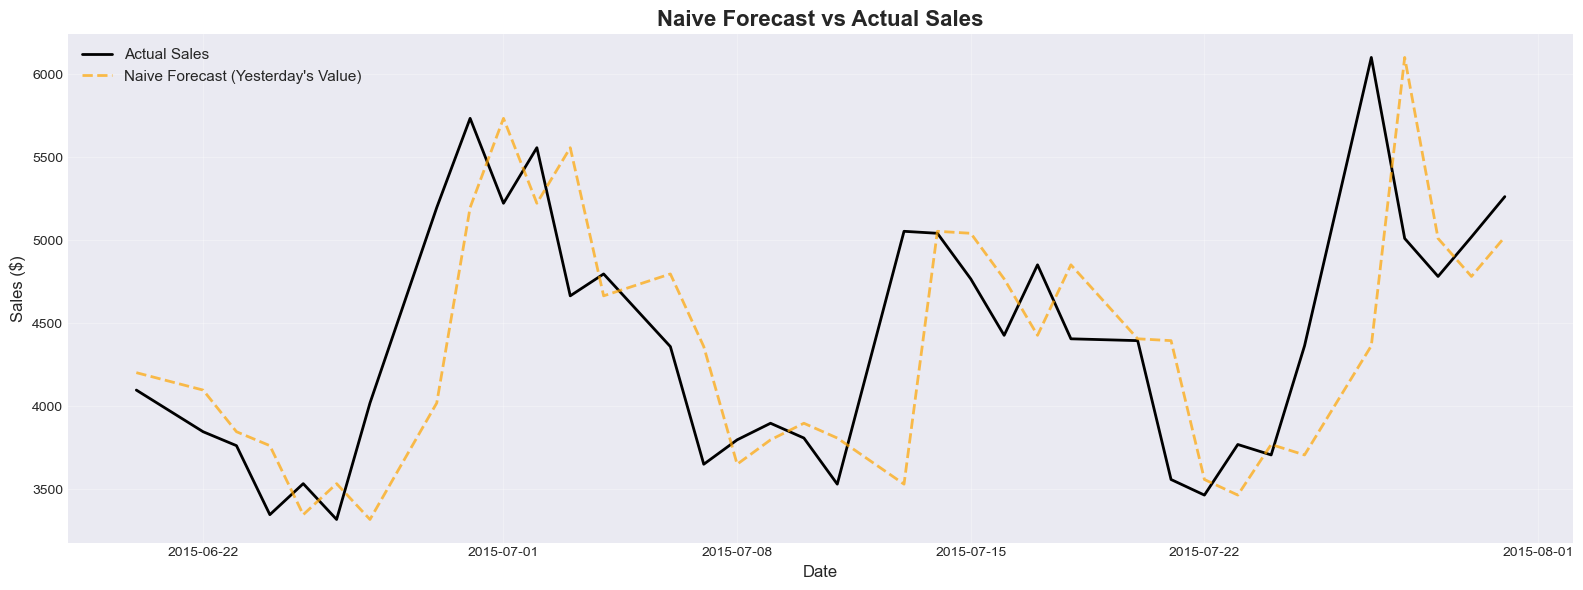

In [8]:
test_naive = test.copy()
test_naive['Naive_Forecast'] = test_naive['Sales'].shift(1)

# Remove first row (has no previous value)
test_naive = test_naive.dropna(subset=['Naive_Forecast'])

# Evaluate
results_naive = evaluate_model(test_naive['Sales'], test_naive['Naive_Forecast'], 'NAIVE FORECAST')

# Visualize
plt.figure(figsize=(16, 6))
plt.plot(test_naive['Date'], test_naive['Sales'], label='Actual Sales', linewidth=2, color='black')
plt.plot(test_naive['Date'], test_naive['Naive_Forecast'], label='Naive Forecast (Yesterday\'s Value)', 
         linewidth=2, alpha=0.7, color='orange', linestyle='--')
plt.title('Naive Forecast vs Actual Sales', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

7-DAY MOVING AVERAGE - PERFORMANCE METRICS
MAE (Mean Absolute Error):     $605.87
RMSE (Root Mean Squared Error): $729.41
MAPE (Mean Absolute % Error):   13.66%
R² Score:                       -0.0273

💡 Interpretation:
   - On average, predictions are off by $606
   - Typical forecast error: 13.7%


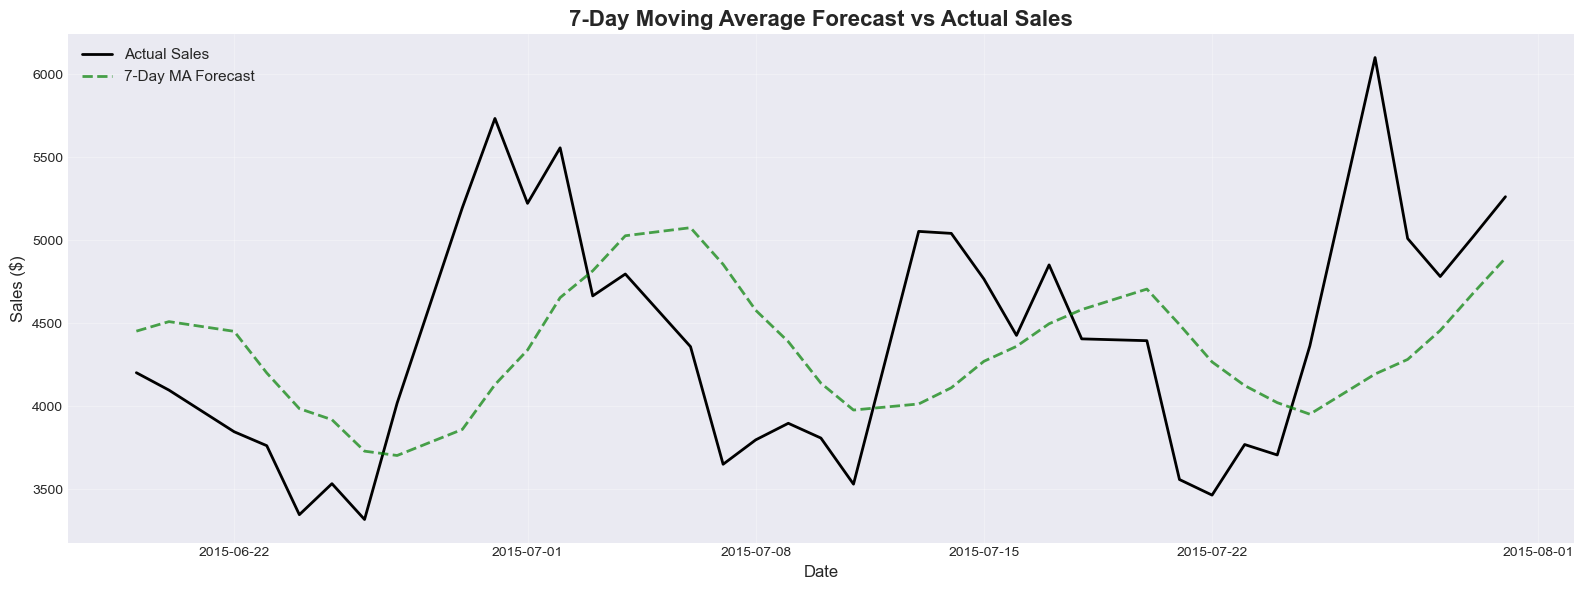

In [9]:
# Calculate 7-day moving average
store_1_open['MA_7'] = store_1_open['Sales'].rolling(window=7, min_periods=1).mean()

# Get predictions for test set
test_ma7 = test.copy()
test_ma7['MA_7_Forecast'] = store_1_open.loc[test.index, 'MA_7'].values

# Remove rows where we don't have enough history
test_ma7 = test_ma7.dropna(subset=['MA_7_Forecast'])

# Evaluate
results_ma7 = evaluate_model(test_ma7['Sales'], test_ma7['MA_7_Forecast'], '7-DAY MOVING AVERAGE')

# Visualize
plt.figure(figsize=(16, 6))
plt.plot(test_ma7['Date'], test_ma7['Sales'], label='Actual Sales', linewidth=2, color='black')
plt.plot(test_ma7['Date'], test_ma7['MA_7_Forecast'], label='7-Day MA Forecast', 
         linewidth=2, alpha=0.7, color='green', linestyle='--')
plt.title('7-Day Moving Average Forecast vs Actual Sales', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

30-DAY MOVING AVERAGE - PERFORMANCE METRICS
MAE (Mean Absolute Error):     $600.25
RMSE (Root Mean Squared Error): $702.99
MAPE (Mean Absolute % Error):   13.93%
R² Score:                       0.0458

💡 Interpretation:
   - On average, predictions are off by $600
   - Typical forecast error: 13.9%


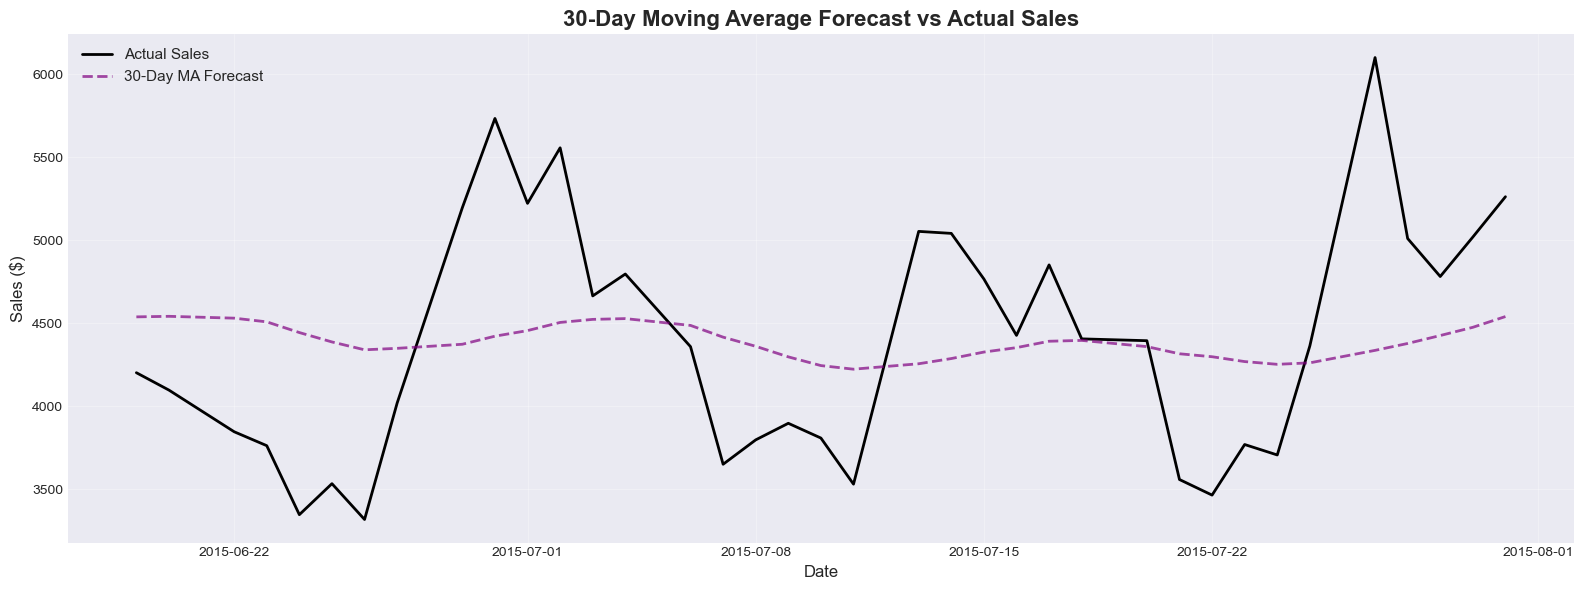

In [10]:
# Calculate 30-day moving average
store_1_open['MA_30'] = store_1_open['Sales'].rolling(window=30, min_periods=1).mean()

# Get predictions for test set
test_ma30 = test.copy()
test_ma30['MA_30_Forecast'] = store_1_open.loc[test.index, 'MA_30'].values

# Remove rows where we don't have enough history
test_ma30 = test_ma30.dropna(subset=['MA_30_Forecast'])

# Evaluate
results_ma30 = evaluate_model(test_ma30['Sales'], test_ma30['MA_30_Forecast'], '30-DAY MOVING AVERAGE')

# Visualize
plt.figure(figsize=(16, 6))
plt.plot(test_ma30['Date'], test_ma30['Sales'], label='Actual Sales', linewidth=2, color='black')
plt.plot(test_ma30['Date'], test_ma30['MA_30_Forecast'], label='30-Day MA Forecast', 
         linewidth=2, alpha=0.7, color='purple', linestyle='--')
plt.title('30-Day Moving Average Forecast vs Actual Sales', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

SEASONAL NAIVE (LAST WEEK) - PERFORMANCE METRICS
MAE (Mean Absolute Error):     $1,105.65
RMSE (Root Mean Squared Error): $1,227.64
MAPE (Mean Absolute % Error):   25.76%
R² Score:                       -1.9100

💡 Interpretation:
   - On average, predictions are off by $1,106
   - Typical forecast error: 25.8%


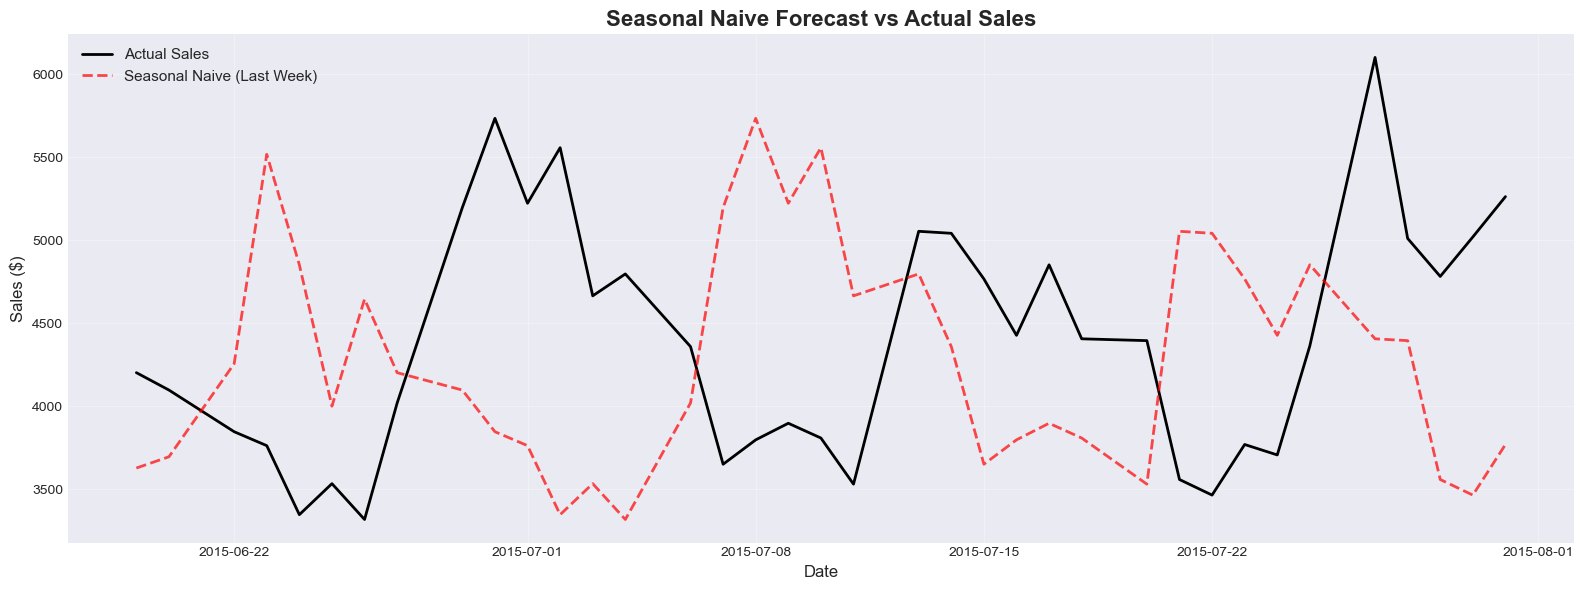

In [11]:
# Seasonal naive: Use same day from last week
test_seasonal = test.copy()
test_seasonal['Seasonal_Naive'] = store_1_open['Sales'].shift(7).loc[test.index].values

# Remove rows without 7-day history
test_seasonal = test_seasonal.dropna(subset=['Seasonal_Naive'])

# Evaluate
results_seasonal = evaluate_model(test_seasonal['Sales'], test_seasonal['Seasonal_Naive'], 
                                  'SEASONAL NAIVE (LAST WEEK)')

# Visualize
plt.figure(figsize=(16, 6))
plt.plot(test_seasonal['Date'], test_seasonal['Sales'], label='Actual Sales', linewidth=2, color='black')
plt.plot(test_seasonal['Date'], test_seasonal['Seasonal_Naive'], label='Seasonal Naive (Last Week)', 
         linewidth=2, alpha=0.7, color='red', linestyle='--')
plt.title('Seasonal Naive Forecast vs Actual Sales', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
comparison = pd.DataFrame([results_naive, results_ma7, results_ma30, results_seasonal])
comparison = comparison.sort_values('MAPE')

print("="*80)
print("🏆 BASELINE MODEL COMPARISON (Sorted by MAPE)")
print("="*80)
display(comparison)

print(f"\n✅ Best Model: {comparison.iloc[0]['Model']}")
print(f"   MAPE: {comparison.iloc[0]['MAPE']:.2f}%")
print(f"   This is our benchmark to beat with ARIMA/Prophet/LSTM!")

🏆 BASELINE MODEL COMPARISON (Sorted by MAPE)


,Model,MAE,RMSE,MAPE,R2
0,NAIVE FORECAST,439.972222,601.348138,9.650142,0.319375
1,7-DAY MOVING AVERAGE,605.868726,729.414398,13.658944,-0.027320
2,30-DAY MOVING AVERAGE,600.248649,702.986886,13.926213,0.045773
3,SEASONAL NAIVE (LAST WEEK),1105.648649,1227.639099,25.757195,-1.910038



✅ Best Model: NAIVE FORECAST
   MAPE: 9.65%
   This is our benchmark to beat with ARIMA/Prophet/LSTM!


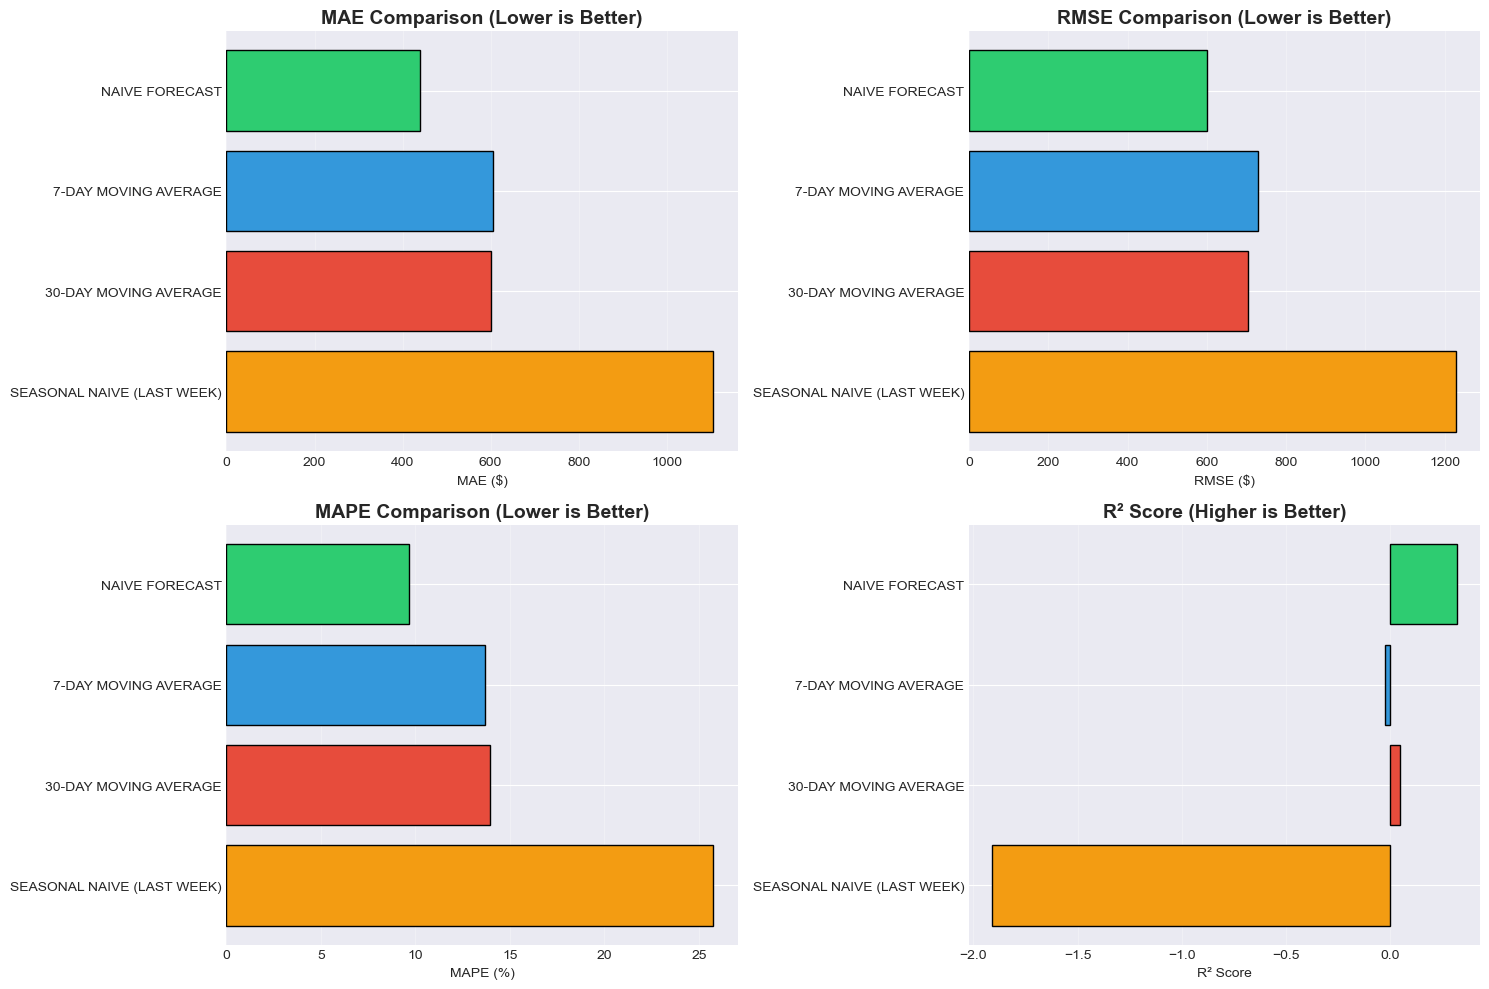

In [13]:
# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# MAE
axes[0, 0].barh(comparison['Model'], comparison['MAE'], color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'], edgecolor='black')
axes[0, 0].set_title('MAE Comparison (Lower is Better)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('MAE ($)')
axes[0, 0].invert_yaxis()
axes[0, 0].grid(axis='x', alpha=0.3)

# RMSE
axes[0, 1].barh(comparison['Model'], comparison['RMSE'], color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'], edgecolor='black')
axes[0, 1].set_title('RMSE Comparison (Lower is Better)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('RMSE ($)')
axes[0, 1].invert_yaxis()
axes[0, 1].grid(axis='x', alpha=0.3)

# MAPE
axes[1, 0].barh(comparison['Model'], comparison['MAPE'], color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'], edgecolor='black')
axes[1, 0].set_title('MAPE Comparison (Lower is Better)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('MAPE (%)')
axes[1, 0].invert_yaxis()
axes[1, 0].grid(axis='x', alpha=0.3)

# R² Score
axes[1, 1].barh(comparison['Model'], comparison['R2'], color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'], edgecolor='black')
axes[1, 1].set_title('R² Score (Higher is Better)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('R² Score')
axes[1, 1].invert_yaxis()
axes[1, 1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


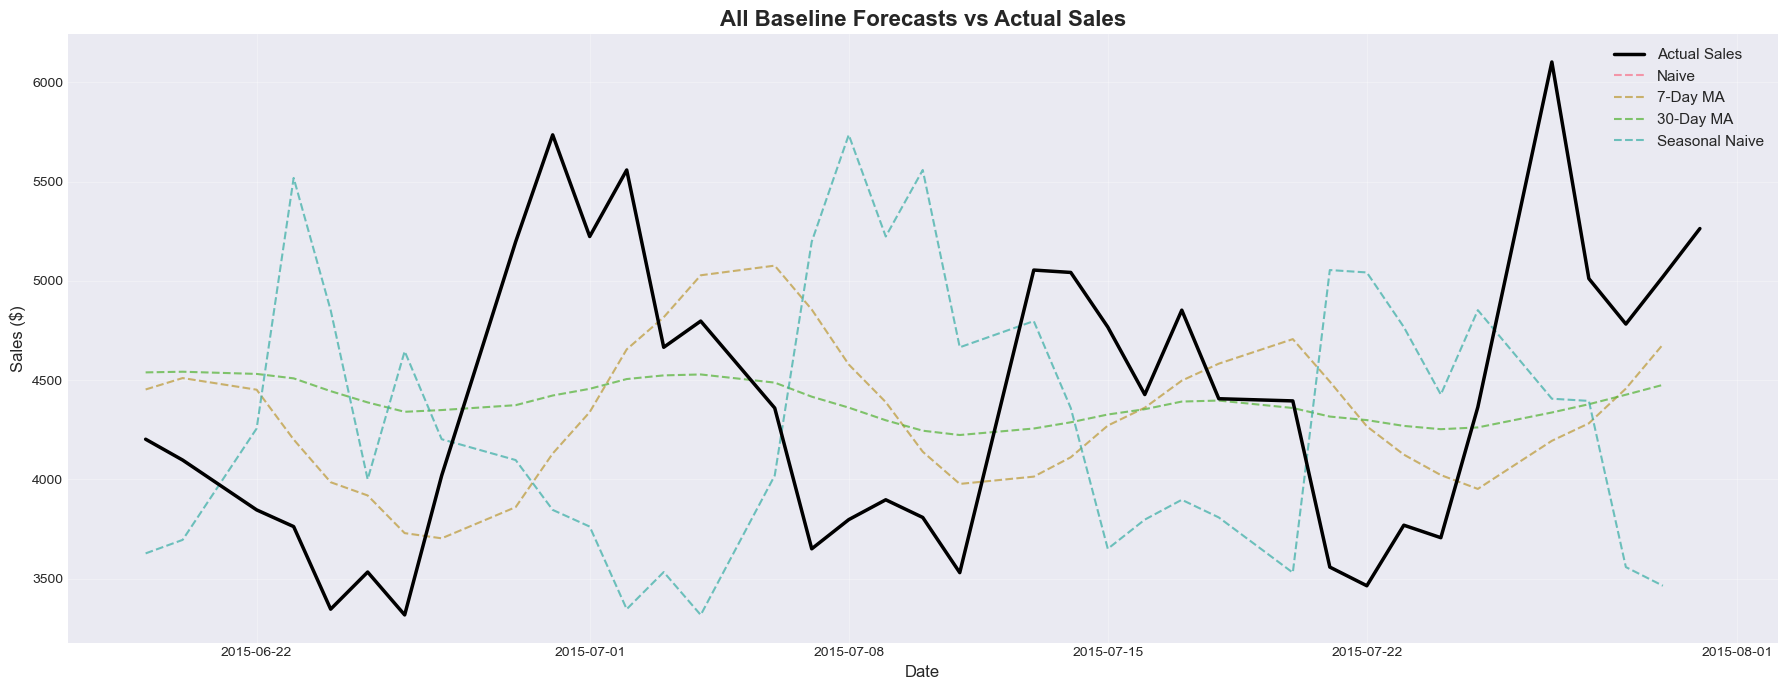

In [14]:
# Plot all forecasts on same chart
plt.figure(figsize=(18, 7))

# Actual sales
plt.plot(test['Date'], test['Sales'], label='Actual Sales', linewidth=2.5, color='black', zorder=5)

# All forecasts (use shortest test set to align)
min_len = min(len(test_naive), len(test_ma7), len(test_ma30), len(test_seasonal))
dates = test['Date'].iloc[:min_len]

plt.plot(dates, test_naive['Naive_Forecast'].iloc[:min_len], label='Naive', linewidth=1.5, alpha=0.7, linestyle='--')
plt.plot(dates, test_ma7['MA_7_Forecast'].iloc[:min_len], label='7-Day MA', linewidth=1.5, alpha=0.7, linestyle='--')
plt.plot(dates, test_ma30['MA_30_Forecast'].iloc[:min_len], label='30-Day MA', linewidth=1.5, alpha=0.7, linestyle='--')
plt.plot(dates, test_seasonal['Seasonal_Naive'].iloc[:min_len], label='Seasonal Naive', linewidth=1.5, alpha=0.7, linestyle='--')

plt.title('All Baseline Forecasts vs Actual Sales', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11, loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

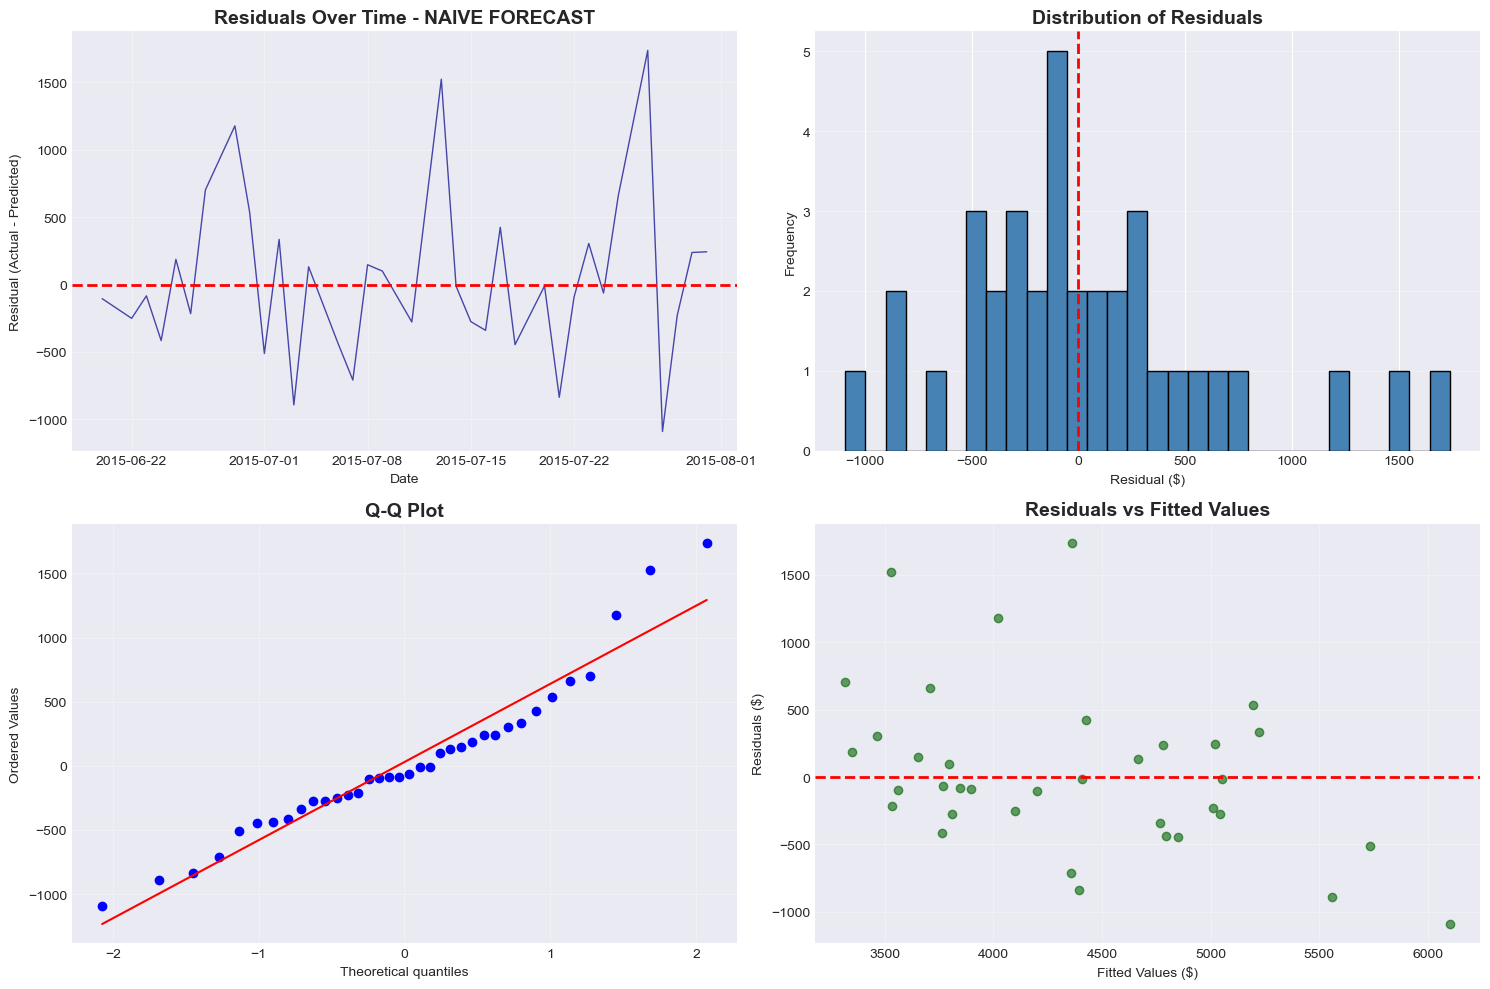

📊 Residual Analysis:
  - Mean residual: $29.47 (should be close to 0)
  - Std deviation: $609.15
  - If residuals are random → Model captures patterns well
  - If residuals have patterns → Room for improvement!


In [15]:
# Calculate residuals for best model
best_model_idx = comparison['MAPE'].idxmin()
best_model_name = comparison.loc[best_model_idx, 'Model']

if 'Seasonal' in best_model_name:
    residuals = test_seasonal['Sales'] - test_seasonal['Seasonal_Naive']
    forecast_dates = test_seasonal['Date']
elif '7-Day' in best_model_name:
    residuals = test_ma7['Sales'] - test_ma7['MA_7_Forecast']
    forecast_dates = test_ma7['Date']
elif '30-Day' in best_model_name:
    residuals = test_ma30['Sales'] - test_ma30['MA_30_Forecast']
    forecast_dates = test_ma30['Date']
else:
    residuals = test_naive['Sales'] - test_naive['Naive_Forecast']
    forecast_dates = test_naive['Date']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuals over time
axes[0, 0].plot(forecast_dates, residuals, linewidth=1, alpha=0.7, color='darkblue')
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_title(f'Residuals Over Time - {best_model_name}', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Residual (Actual - Predicted)')
axes[0, 0].grid(alpha=0.3)

# Histogram of residuals
axes[0, 1].hist(residuals, bins=30, edgecolor='black', color='steelblue')
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_title('Distribution of Residuals', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Residual ($)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(axis='y', alpha=0.3)

# Q-Q plot (check if residuals are normally distributed)
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot', fontsize=14, fontweight='bold')
axes[1, 0].grid(alpha=0.3)

# Residuals vs Fitted
if 'Seasonal' in best_model_name:
    fitted = test_seasonal['Seasonal_Naive']
elif '7-Day' in best_model_name:
    fitted = test_ma7['MA_7_Forecast']
elif '30-Day' in best_model_name:
    fitted = test_ma30['MA_30_Forecast']
else:
    fitted = test_naive['Naive_Forecast']

axes[1, 1].scatter(fitted, residuals, alpha=0.6, color='darkgreen')
axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1, 1].set_title('Residuals vs Fitted Values', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Fitted Values ($)')
axes[1, 1].set_ylabel('Residuals ($)')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("📊 Residual Analysis:")
print(f"  - Mean residual: ${residuals.mean():,.2f} (should be close to 0)")
print(f"  - Std deviation: ${residuals.std():,.2f}")
print(f"  - If residuals are random → Model captures patterns well")
print(f"  - If residuals have patterns → Room for improvement!")


In [16]:
import os
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables', exist_ok=True)

comparison.to_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/baseline_model_comparison.csv', index=False)
print("✅ Results saved to: results/tables/baseline_model_comparison.csv")

# Save best model predictions for later use
if 'Seasonal' in best_model_name:
    test_seasonal.to_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/baseline_predictions.csv', index=False)
elif '7-Day' in best_model_name:
    test_ma7.to_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/baseline_predictions.csv', index=False)

print("✅ Best model predictions saved!")

✅ Results saved to: results/tables/baseline_model_comparison.csv
✅ Best model predictions saved!


In [17]:
print(f"\n✅ BASELINE MODELS ESTABLISHED:")
print(f"  Best Model: {comparison.iloc[0]['Model']}")
print(f"  Benchmark MAPE: {comparison.iloc[0]['MAPE']:.2f}%")
print(f"  Average Error: ${comparison.iloc[0]['MAE']:,.0f} per day")

print(f"\n📈 WHAT THIS MEANS:")
if comparison.iloc[0]['MAPE'] < 15:
    print("  ✅ Baseline is already quite good (<15% MAPE)")
    print("  → Advanced models should aim for <10% MAPE")
elif comparison.iloc[0]['MAPE'] < 20:
    print("  ✅ Baseline is decent (15-20% MAPE)")
    print("  → Advanced models should aim for <12% MAPE")
else:
    print("  ⚠️ Baseline is weak (>20% MAPE)")
    print("  → Lots of room for improvement with advanced models")




✅ BASELINE MODELS ESTABLISHED:
  Best Model: NAIVE FORECAST
  Benchmark MAPE: 9.65%
  Average Error: $440 per day

📈 WHAT THIS MEANS:
  ✅ Baseline is already quite good (<15% MAPE)
  → Advanced models should aim for <10% MAPE
